# Module 3 (CO3): Ensemble Learning (Random Forest, Gradient Boosting, XGBoost)
**Project**: Anti-Money Laundering Detection (IBM Benchmark)  
**Focus**: Advanced ensemble algorithms, dynamic ROC curves, Precision-Recall curves, and Feature Importance.

In [1]:
# 1. Load Data & Train Ensemble Models
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import xgboost as xgb
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                             roc_auc_score, roc_curve, precision_recall_curve)

# Load dataset
df = pd.read_csv(r'../data/ibm_aml_transactions.csv')
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['hour'] = df['Timestamp'].dt.hour
df['dayofweek'] = df['Timestamp'].dt.dayofweek
df['is_weekend'] = df['dayofweek'].isin([5, 6]).astype(int)
df['is_night'] = df['hour'].isin([0, 1, 2, 3, 4, 5, 22, 23]).astype(int)
df['is_cross_bank'] = (df['From Bank'] != df['To Bank']).astype(int)
df['amount_diff'] = np.abs(df['Amount Paid'] - df['Amount Received'])
df['log_amount_paid'] = np.log1p(df['Amount Paid'])
df['structuring_flag'] = ((df['Amount Paid'] >= 8500) & (df['Amount Paid'] < 10000)).astype(int)

format_dummies = pd.get_dummies(df['Payment Format'], prefix='format', drop_first=False).astype(int)
df = pd.concat([df, format_dummies], axis=1)

feature_cols = ['Amount Paid', 'Amount Received', 'amount_diff', 'log_amount_paid', 'is_cross_bank', 'structuring_flag', 'hour', 'dayofweek', 'is_weekend', 'is_night'] + format_dummies.columns.tolist()
X = df[feature_cols]
y = df['Is Laundering']

# 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("Training Random Forest Classifier...")
rf = RandomForestClassifier(n_estimators=50, max_depth=12, class_weight='balanced', n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)

print("Training XGBoost Classifier...")
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_clf = xgb.XGBClassifier(n_estimators=50, max_depth=6, scale_pos_weight=scale_pos_weight, random_state=42, n_jobs=-1, eval_metric='logloss')
xgb_clf.fit(X_train, y_train)

print("Training Gradient Boosting Classifier...")
gb = GradientBoostingClassifier(n_estimators=35, max_depth=5, random_state=42)
gb.fit(X_train, y_train)
print("All ensemble models trained successfully!")


Training Random Forest Classifier...
Training XGBoost Classifier...
Training Gradient Boosting Classifier...
All ensemble models trained successfully!


## 2. Live Ensemble Evaluation Metrics

In [2]:
# Calculate ensemble predictions & metrics dynamically
ensembles = {'Random Forest': rf, 'Tuned XGBoost': xgb_clf, 'Gradient Boosting': gb}
ensemble_results = []
probs_dict = {}

for name, clf in ensembles.items():
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    probs_dict[name] = y_prob
    ensemble_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

ens_df = pd.DataFrame(ensemble_results)
print("Ensemble Performance on Holdout Test Set (20,000 Transactions):")
display(ens_df.round(4))


Ensemble Performance on Holdout Test Set (20,000 Transactions):


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.9172,0.3696,0.8502,0.5152,0.9215
1,Tuned XGBoost,0.9140,0.3595,0.8483,0.5050,0.9189
2,Gradient Boosting,0.9592,0.6886,0.3845,0.4935,0.9198


## 3. Dynamic Visualizations: ROC Curves, PR Curves & Feature Importance

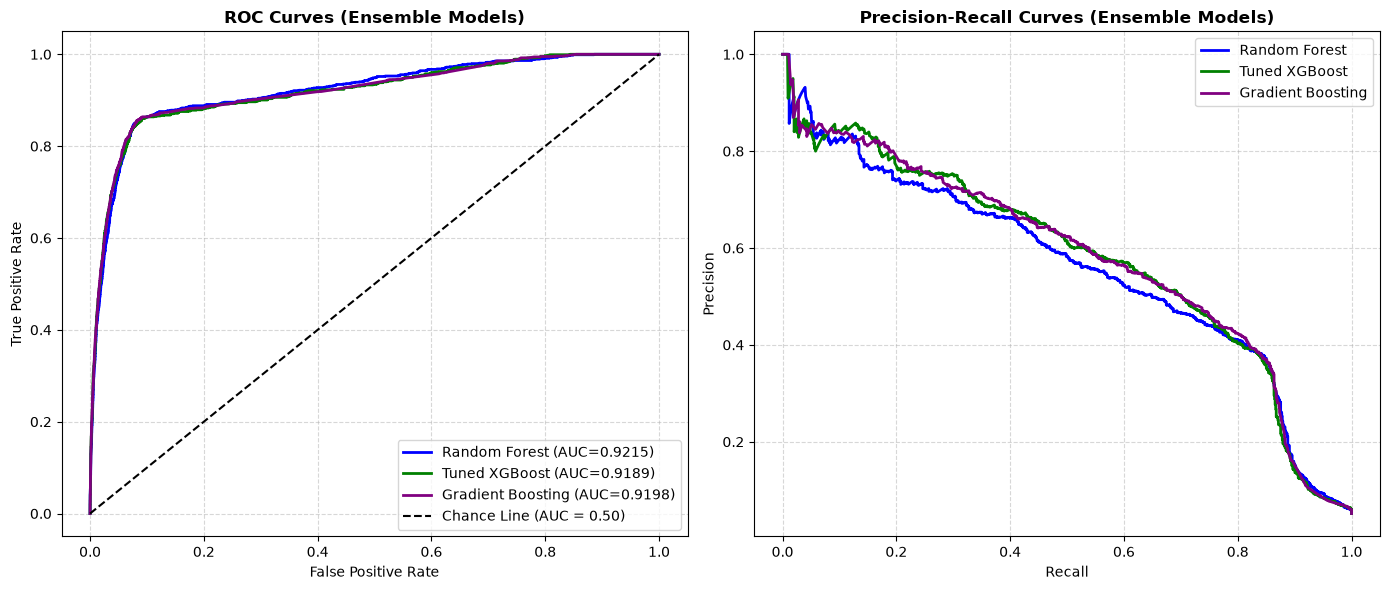

C:\Users\Vishnu\AppData\Local\Temp\ipykernel_23068\1196560509.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df.head(12), x='Importance', y='Feature', palette='Blues_r')


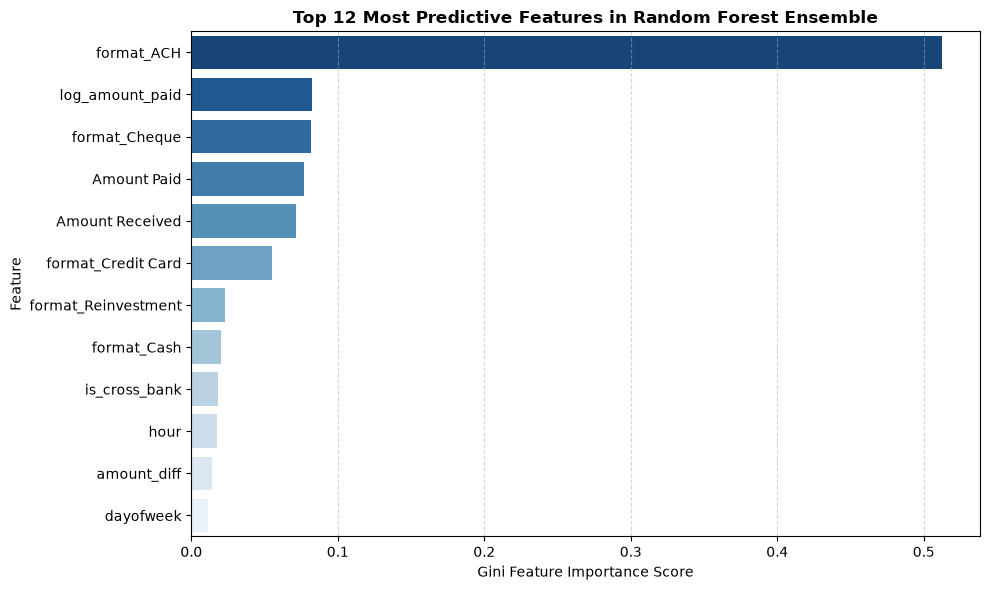

In [3]:
# Visualization: Dynamic ROC Curves and Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. ROC Curves
colors = {'Random Forest': 'blue', 'Tuned XGBoost': 'green', 'Gradient Boosting': 'purple'}
for name, y_prob in probs_dict.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc_val:.4f})", color=colors[name], linewidth=2)

axes[0].plot([0, 1], [0, 1], 'k--', label='Chance Line (AUC = 0.50)')
axes[0].set_title('ROC Curves (Ensemble Models)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Precision-Recall Curves
for name, y_prob in probs_dict.items():
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    axes[1].plot(recall, precision, label=name, color=colors[name], linewidth=2)

axes[1].set_title('Precision-Recall Curves (Ensemble Models)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Visualization: Feature Importance (Random Forest Champion)
importances = rf.feature_importances_
feat_df = pd.DataFrame({'Feature': feature_cols, 'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_df.head(12), x='Importance', y='Feature', palette='Blues_r')
plt.title('Top 12 Most Predictive Features in Random Forest Ensemble', fontsize=12, fontweight='bold')
plt.xlabel('Gini Feature Importance Score')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
